# Validation folds, metrics and baseline models

CRISP-DM phase 4/5. This notebook sets up the evaluation that every model will use, and runs the
simple baselines. The baselines are the minimum level the machine learning models have to beat.

Steps:
1. load the data and build the modelling table (from notebook 03)
2. make the 3 rolling-origin folds (`src/folds.py`)
3. run the baselines: naive, 26-week moving average, Linear Regression
4. score them with `src/metrics.py` (RMSE, MAE, RMSLE, WAPE, bias, over-forecast %)
5. save the results table and the predictions (needed later for the simulation)

In [1]:
import sys
sys.path.append('..')
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression

from src.features import build_dataset, HISTORY_COLS, TARGET_WEEK_COLS
from src.folds import ORIGINS, split_fold
from src.metrics import all_metrics
from src.plot_settings import set_ieee_style, save_fig, ONE_COL

set_ieee_style()
pd.set_option('display.max_columns', 30)
os.makedirs('../results/tables', exist_ok=True)

## 1. Load data

In [2]:
df = pd.read_parquet('../data/processed/clean.parquet')
hist = pd.read_parquet('../data/processed/history_features.parquet')

data = build_dataset(df, hist)
print(data.shape)

(4407292, 32)


## 2. Rolling-origin folds

For each fold we stand at origin week T. Training uses every example whose **target** week is T or
earlier, so no orders after week T are used. The test set is weeks T+1 to T+10, all forecast from origin T.

In [3]:
for origin in ORIGINS:
    train, test = split_fold(data, origin)
    print(f'origin {origin}: train {len(train):,} rows (target weeks {train.week.min()}-{train.week.max()}), '
          f'test {len(test):,} rows (weeks {test.week.min()}-{test.week.max()}, h {test.h.min()}-{test.h.max()})')

origin 115: train 3,422,542 rows (target weeks 2-115), test 32,834 rows (weeks 116-125, h 1-10)


origin 125: train 3,750,882 rows (target weeks 2-125), test 32,820 rows (weeks 126-135, h 1-10)


origin 135: train 4,079,082 rows (target weeks 2-135), test 32,821 rows (weeks 136-145, h 1-10)


In [4]:
# check: nothing in the training set is after the origin, and the test rows really start at the origin
for origin in ORIGINS:
    train, test = split_fold(data, origin)
    assert train['week'].max() <= origin
    assert (test['origin_week'] == origin).all()
    assert (test['week'] - test['h'] == origin).all()
print('folds ok')

folds ok


## 3. Baseline models

1. **Naive** - next weeks will have the same orders as the last week we know (`orders_last_known`).
2. **Moving average** - the average of the last 26 weeks (`orders_mean_26`). This average is on the log scale,
   so after converting back it is a geometric mean, which is less affected by spikes.
3. **Linear Regression** - on the same inputs as the ML models, except the centre and meal ids (too many
   categories for a linear model).

All models work on log(1 + orders), the predictions are converted back with exp(x) - 1.

A few test series have no history at the origin (new meals). For them the naive and moving average use the
median log orders of that meal in the training weeks.

In [5]:
def fill_new_series(values, train, test):
    # for series with no history: use the median of the same meal in the training weeks, else overall median
    meal_median = train.groupby('meal_id')['log_orders'].median()
    values = values.fillna(test['meal_id'].map(meal_median))
    return values.fillna(train['log_orders'].median())


def naive_forecast(train, test):
    log_pred = fill_new_series(test['orders_last_known'], train, test)
    return np.expm1(log_pred)


def moving_average_forecast(train, test):
    log_pred = fill_new_series(test['orders_mean_26'], train, test)
    return np.expm1(log_pred)

In [6]:
# inputs for linear regression
lr_numeric = ['h'] + HISTORY_COLS + TARGET_WEEK_COLS + ['price_vs_mean', 'price_vs_last', 'op_area']
lr_categorical = ['center_type', 'category', 'cuisine', 'region_code']

def make_linear_model():
    # imputer, scaler and encoder are fitted inside the pipeline -> only on the training data of each fold
    numeric = Pipeline([('impute', SimpleImputer(strategy='median')),
                        ('scale', StandardScaler())])
    prep = ColumnTransformer([('num', numeric, lr_numeric),
                              ('cat', OneHotEncoder(handle_unknown='ignore'), lr_categorical)])
    return Pipeline([('prep', prep), ('model', LinearRegression())])


def linear_forecast(train, test):
    model = make_linear_model()
    model.fit(train[lr_numeric + lr_categorical], train['log_orders'])
    log_pred = model.predict(test[lr_numeric + lr_categorical])
    # keep predictions inside the range seen in training (a linear model can go very high or below 0)
    log_pred = np.clip(log_pred, 0, train['log_orders'].max())
    return np.expm1(log_pred)

## 4. Run all baselines on all folds

In [7]:
baselines = {
    'Naive': naive_forecast,
    'Moving average (26 wk)': moving_average_forecast,
    'Linear Regression': linear_forecast,
}

results = []
predictions = []

for origin in ORIGINS:
    train, test = split_fold(data, origin)
    pred_table = test[['series_id', 'center_id', 'meal_id', 'week', 'h', 'num_orders']].copy()
    pred_table['origin'] = origin

    for name, forecast in baselines.items():
        pred = forecast(train, test)
        pred_table[name] = pred.values if hasattr(pred, 'values') else pred

        row = {'model': name, 'origin': origin}
        row.update(all_metrics(test['num_orders'], pred_table[name]))
        results.append(row)
        print(f'origin {origin}  {name:24s} WAPE {row["WAPE"]:.1f}%')

    predictions.append(pred_table)

results = pd.DataFrame(results)
predictions = pd.concat(predictions, ignore_index=True)

origin 115  Naive                    WAPE 52.1%
origin 115  Moving average (26 wk)   WAPE 39.1%


origin 115  Linear Regression        WAPE 32.0%


origin 125  Naive                    WAPE 52.2%
origin 125  Moving average (26 wk)   WAPE 41.9%


origin 125  Linear Regression        WAPE 33.0%


origin 135  Naive                    WAPE 48.5%
origin 135  Moving average (26 wk)   WAPE 34.2%


origin 135  Linear Regression        WAPE 31.0%


## 5. Results

Per fold, and the average over the 3 folds (this is the number that goes in the report).

In [8]:
results.round(2)

,model,origin,RMSE,MAE,RMSLE,WAPE,Bias,Over %
0,Naive,115,310.93,132.81,0.83,52.09,-9.73,51.08
1,Moving average (26 wk),115,260.51,99.62,0.64,39.07,-28.58,53.85
2,Linear Regression,115,191.84,81.55,0.52,31.99,-24.63,49.05
3,Naive,125,357.95,137.34,0.83,52.15,-33.50,46.10
4,Moving average (26 wk),125,314.33,110.34,0.63,41.90,-36.47,51.42
5,Linear Regression,125,234.85,86.91,0.50,33.00,-36.58,45.12
6,Naive,135,214.22,110.31,0.77,48.53,10.31,53.07
7,Moving average (26 wk),135,135.87,77.73,0.59,34.20,-4.74,51.95
8,Linear Regression,135,122.87,70.45,0.50,30.99,-21.84,44.18


In [9]:
model_order = list(baselines.keys())
summary = results.groupby('model')[['RMSE', 'MAE', 'RMSLE', 'WAPE', 'Bias', 'Over %']].mean().loc[model_order]
summary.round(2)

,RMSE,MAE,RMSLE,WAPE,Bias,Over %
model,,,,,,
Naive,294.37,126.82,0.81,50.92,-10.97,50.08
Moving average (26 wk),236.90,95.90,0.62,38.39,-23.26,52.41
Linear Regression,183.19,79.64,0.51,31.99,-27.68,46.12


In [10]:
# also the spread between folds - shows how stable each model is
results.groupby('model')['WAPE'].agg(['mean', 'std', 'min', 'max']).loc[model_order].round(2)

,mean,std,min,max
model,,,,
Naive,50.92,2.07,48.53,52.15
Moving average (26 wk),38.39,3.90,34.20,41.90
Linear Regression,31.99,1.00,30.99,33.00


### Error by horizon

Forecasts further ahead should be worse. WAPE per horizon, all 3 folds together.

In [11]:
wape_h = {}
for name in model_order:
    err = (predictions[name] - predictions['num_orders']).abs()
    wape_h[name] = err.groupby(predictions['h']).sum() / predictions.groupby('h')['num_orders'].sum() * 100
wape_h = pd.DataFrame(wape_h)
wape_h.round(1)

,Naive,Moving average (26 wk),Linear Regression
h,,,
1,33.8,34.6,31.8
2,44.7,34.0,29.7
3,54.7,38.4,30.9
4,53.0,37.6,29.9
5,52.4,38.1,31.4
6,49.5,40.8,31.8
7,54.8,41.6,33.3
8,56.8,40.7,34.4
9,54.4,39.3,33.6


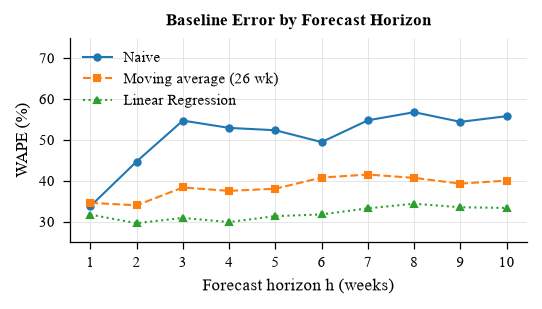

In [12]:
fig, ax = plt.subplots(figsize=(ONE_COL, 1.95))
ax.plot(wape_h.index, wape_h['Naive'], color='tab:blue', marker='o', markersize=3, label='Naive')
ax.plot(wape_h.index, wape_h['Moving average (26 wk)'], color='tab:orange', linestyle='--', marker='s', markersize=3, label='Moving average (26 wk)')
ax.plot(wape_h.index, wape_h['Linear Regression'], color='tab:green', linestyle=':', marker='^', markersize=3, label='Linear Regression')
ax.set_title('Baseline Error by Forecast Horizon')
ax.set_xlabel('Forecast horizon h (weeks)')
ax.set_ylabel('WAPE (%)')
ax.set_xticks(range(1, 11))
ax.set_ylim(25, 75)
ax.legend(loc='upper left', ncol=1)
save_fig(fig, 'fig22_baseline_wape_by_horizon')
plt.show()

### Comparison with Panda and Mohanty (2023)

They report RMSE 18.83 and RMSLE 0.28 for their best model (LSTM). Our numbers are not directly comparable:
they used lags 1-10 to forecast 10 weeks ahead (orders that would not be known yet), features calculated
over all weeks including the test weeks, and a single test period. Here every feature only uses information
available at the origin, and the results are averaged over 3 folds. The baselines above are the fair
reference point for our own models.

## 6. Save

In [13]:
results.to_csv('../results/tables/04_baseline_results_per_fold.csv', index=False)
summary.round(3).to_csv('../results/tables/04_baseline_results_mean.csv')
predictions.to_parquet('../data/processed/predictions_baselines.parquet', index=False)

print(predictions.shape)
predictions.head()

(98475, 10)


,series_id,center_id,meal_id,week,h,num_orders,origin,Naive,Moving average (26 wk),Linear Regression
0,101062,10,1062,116,1,1283,115,1093.999742,902.981117,2063.939770
1,101109,10,1109,116,1,850,115,1268.000231,1323.483596,1028.435127
2,101198,10,1198,116,1,366,115,485.999888,372.113843,378.079134
3,101207,10,1207,116,1,135,115,148.000000,206.605663,216.763261
4,101216,10,1216,116,1,162,115,202.000044,128.585485,104.979556


## Summary

| Model | WAPE (mean of 3 folds) | RMSE | RMSLE | Over-forecast % |
|---|---|---|---|---|
| Naive | 50.9% | 294 | 0.81 | 50% |
| Moving average (26 wk) | 38.4% | 237 | 0.62 | 52% |
| Linear Regression | **32.0%** | **183** | **0.51** | 46% |

- Linear Regression is the best baseline in every fold (WAPE 31-33%) and the most stable between folds
  (std 1.0). This is the number the ML models in notebook 05 have to beat.
- The naive forecast is fine for 1 week ahead (34%) but gets much worse after that (45-57%), which matches the
  low autocorrelation found in notebook 02. The 26-week average is more stable over the horizon.
- Error grows only a little with the horizon for Linear Regression (about 30% -> 33%), because it uses the
  price and promotion of the target week, which are known in advance.
- All three baselines have a **negative bias** (they forecast too low on average, -11 to -28 orders). This is
  expected: training on log(orders) gives forecasts close to the median, which is below the mean for skewed
  demand (Kolassa). If these forecasts were used as orders, there would be more shortages than waste - this is
  exactly what quantile regression (notebook 06) should fix.
- Fold 2 (weeks 126-135) is the hardest for all models.

Saved: `results/tables/04_baseline_results_per_fold.csv`, `04_baseline_results_mean.csv` and
`data/processed/predictions_baselines.parquet` (used later in the simulation).
